# Predictive Maintenance — Preprocessing & Exploratory Data Analysis (EDA)
### Dataset: UCI AI4I 2020 Predictive Maintenance Dataset
**Objective:** Inspect raw sensor data, perform data cleaning and statistical checks, generate EDA visualizations, and carry out feature encoding and scaling for machine failure classification.

## 1. Import Libraries

In [253]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


## 2. Load the Dataset & Initial Inspection

In [254]:
# Load the CSV file
csv_path = 'ai4i2020.csv'
df = pd.read_csv(csv_path)

# Show the first 5 rows
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [255]:
# Dataset column information and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [256]:
# Descriptive statistics of sensor readings
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


## 3. Data Cleaning & Integrity Verification
- Check and remove duplicate rows.
- Check and handle missing/null values.
- Drop non-predictive identifiers (`UDI`, `Product ID`).

In [257]:
# Count the missing values in each column
missing_counts = df.isnull().sum()

# Show only the columns that have missing values
print(missing_counts[missing_counts > 0])

# Remove duplicate rows from the dataset
df = df.drop_duplicates().copy()

# Remove rows where the Machine failure value is missing
df = df.dropna(subset=['Machine failure']).copy()

# Change Machine failure values to whole numbers, such as 0 and 1
df['Machine failure'] = df['Machine failure'].astype(int)

Series([], dtype: int64)


In [258]:
# List the sensor columns that may have missing values
sensor_features = [
    'Air temperature [K]', 'Process temperature [K]',
    'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]'
]

# Fill missing sensor values with the middle value in that column
for col in sensor_features:
    df[col] = df[col].fillna(df[col].median())

# Fill missing machine types with the type that appears most often
df['Type'] = df['Type'].fillna(df['Type'].mode().iloc[0])

## 4. Exploratory Data Analysis (EDA)
Visual analysis of target distribution, sensor distributions, correlations, and feature interactions.

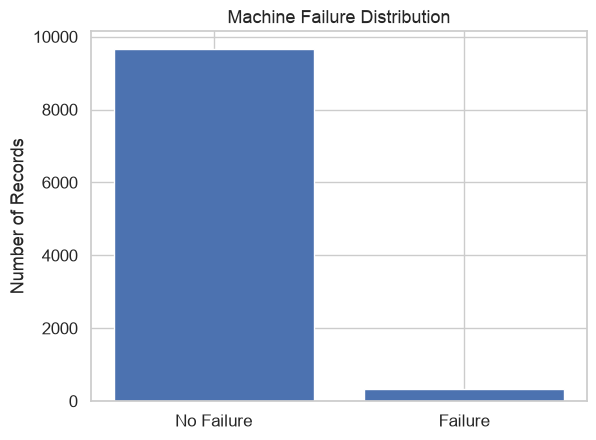

In [259]:
# Count how many machines had no failure (0) and had a failure (1)
counts = df['Machine failure'].value_counts().reindex([0, 1], fill_value=0)

# Draw a bar for each group
plt.bar(['No Failure', 'Failure'], counts.values)

# Add a title and label to the side
plt.title('Machine Failure Distribution')
plt.ylabel('Number of Records')

# Show the chart
plt.show()

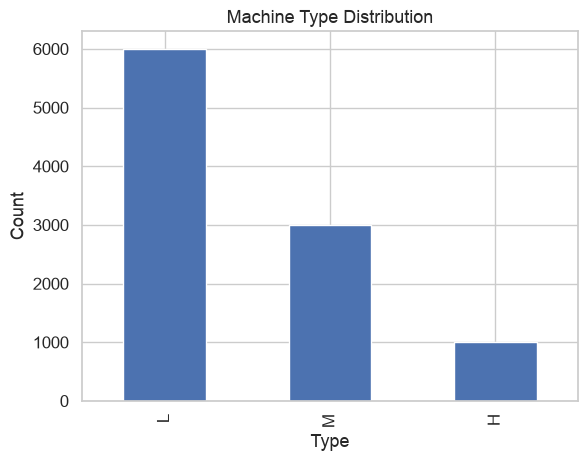

In [260]:
# Count each machine type and draw a bar chart
df['Type'].value_counts().plot(kind='bar')

# Add a title and labels to the chart
plt.title('Machine Type Distribution')
plt.xlabel('Type')
plt.ylabel('Count')

# Show the chart
plt.show()

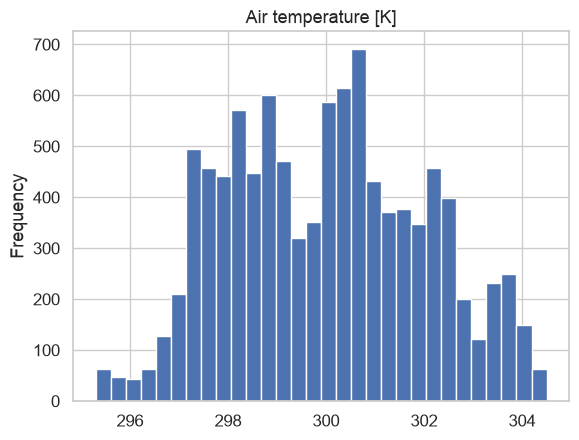

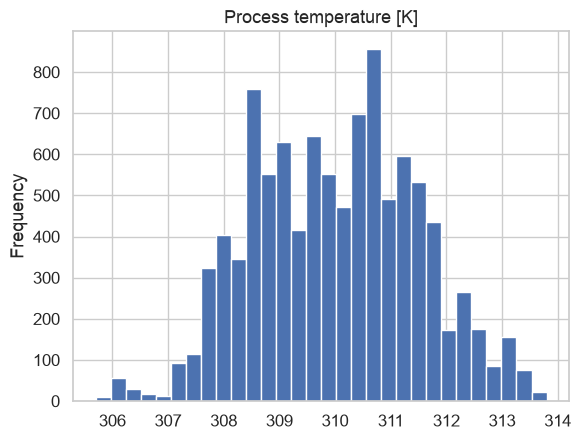

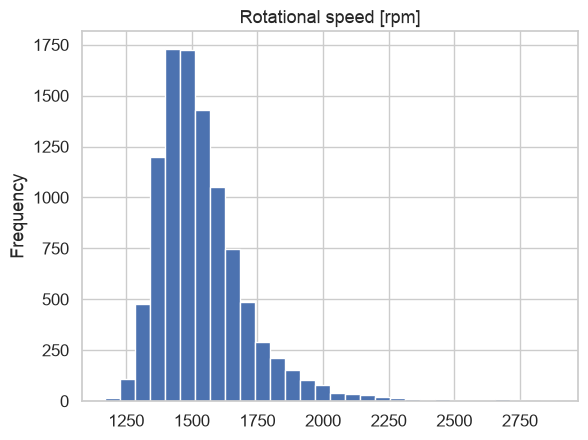

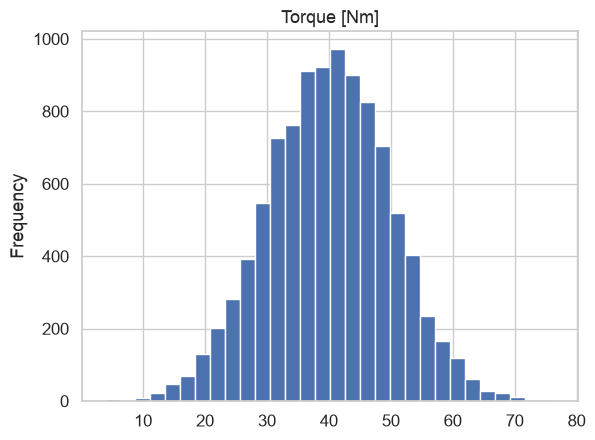

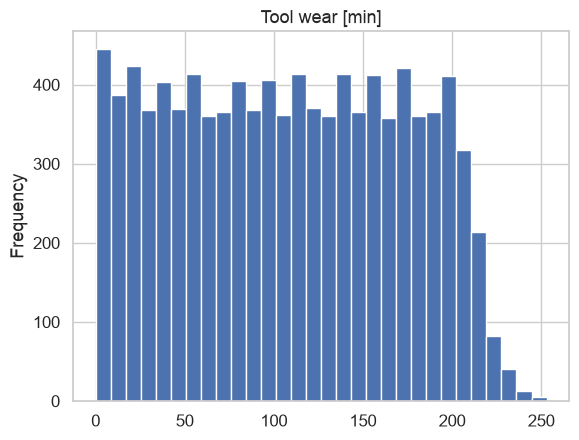

In [261]:
# Make a histogram for each sensor column
for col in sensor_features:
    df[col].plot(kind='hist', bins=30, title=col)

    # Show the histogram
    plt.show()

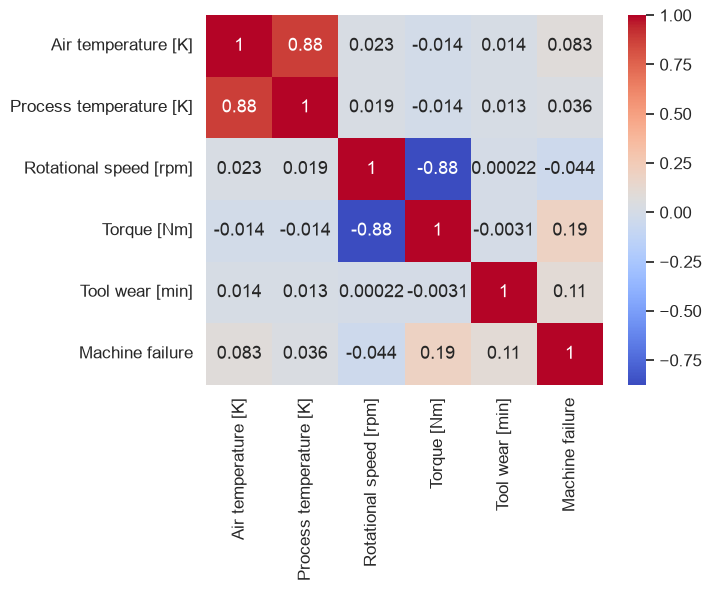

In [262]:
# Select the sensor columns and the Machine failure column
columns = sensor_features + ['Machine failure']

# Make a heatmap to show how these columns are related
sns.heatmap(df[columns].corr(), annot=True, cmap='coolwarm')

# Show the heatmap
plt.show()

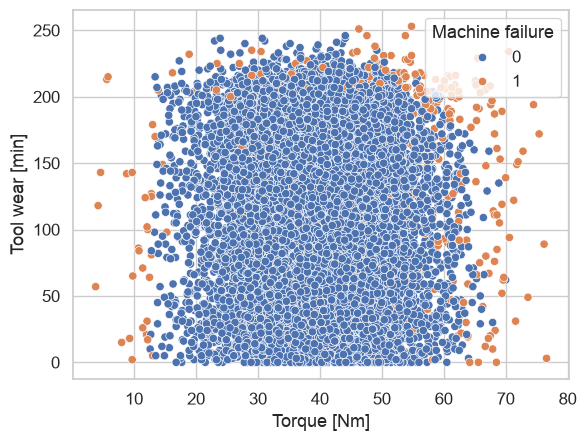

In [263]:
# Make a scatter plot to compare torque and tool wear
# Each dot shows one machine record; its colour shows failure status
sns.scatterplot(
    data=df,
    x='Torque [Nm]',
    y='Tool wear [min]',
    hue='Machine failure'
)

# Show the chart
plt.show()

## 5. Feature Engineering & Preprocessing
- Drop non-predictive columns (`UDI`, `Product ID`, and specific failure modes `TWF`, `HDF`, `PWF`, `OSF`, `RNF` if present).
- One-hot encode the categorical variable `Type` using `pandas.get_dummies` with `drop_first=True`.
- Perform an 80/20 stratified train-test split (`stratify=y`, `random_state=42`).
- Scale features with `StandardScaler` (fitted strictly on the training set to prevent data leakage).

In [264]:
# Choose the machine type and sensor readings for the model
feature_cols = ['Type'] + sensor_features

# Choose what the model will predict
target_col = 'Machine failure'

# Change machine types (L, M, H) into numbers the model can use
X = pd.get_dummies(df[feature_cols], columns=['Type'], drop_first=True, dtype=int)

# Store the answers the model will learn to predict
y = df[target_col]

# Show the first 5 rows of the input data
display(X.head())

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,1
1,298.2,308.7,1408,46.3,3,1,0
2,298.1,308.5,1498,49.4,5,1,0
3,298.2,308.6,1433,39.5,7,1,0
4,298.2,308.7,1408,40.0,9,1,0


In [265]:
# Split the data: 80% to train the model and 20% to test it
# Keep about the same number of failures in both groups
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Show how many rows and columns are in each group
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8000, 7)
Testing set: (2000, 7)


In [266]:
# Create a tool to put the feature values on a similar scale
scaler = StandardScaler()

# Learn the scaling from the training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaling on the test data
X_test_scaled = scaler.transform(X_test)

# Put the scaled training data in a table with column names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

# Show the summary, rounded to 2 decimal places
display(X_train_scaled_df.describe().round(2))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.36,-2.91,-2.05,-3.61,-1.69,-1.23,-0.65
25%,-0.85,-0.82,-0.65,-0.68,-0.86,-1.23,-0.65
50%,0.05,0.06,-0.20,0.01,-0.01,0.81,-0.65
75%,0.75,0.74,0.41,0.68,0.87,0.81,1.54
max,2.25,2.56,7.44,3.65,2.28,0.81,1.54
